# Part 4F: Stock or ETF?

**Question.** (1) A trader who is bullish on NVDA on a day it presents new chips: buy the stock or the ETF? (2) A long-term investor who believes NVDA will do well over the next year but may see volatility: buy the stock or the ETF?

The supporting calculation below measures how much the daily reset costs in this sample, using logarithmic returns so the effect can be isolated from the trend.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format

# Paths are relative to part4/python_source
DATA = next(Path("../../data/raw").glob("*part 4*.xlsx"))
FIG = Path("../../output/figures"); FIG.mkdir(parents=True, exist_ok=True)
TAB = Path("../../output/tables"); TAB.mkdir(parents=True, exist_ok=True)

# 5 header rows, then newest-first daily total returns in decimals (0.01 = 1%)
raw = pd.read_excel(DATA, header=None, skiprows=5, names=["date", "NVDA", "NVDL"])
raw["date"] = pd.to_datetime(raw["date"])
df = raw.sort_values("date").set_index("date")   # ascending order needed before compounding
print(len(df), "trading days,", df.index.min().date(), "to", df.index.max().date())

147 trading days, 2024-02-01 to 2024-08-30


In [2]:
# Log growth of a daily-reset 2x ETF (fees and financing excluded) vs twice the stock's log growth.
log_stock = np.log1p(df["NVDA"])
log_2x_ideal = np.log1p(2 * df["NVDA"])             # an ideal 2x fund with no fees or financing
vol_drag_total = log_2x_ideal.sum() - 2 * log_stock.sum()
days = len(df)

summary = pd.Series({
    "Days in sample": days,
    "Sum of daily log returns, NVDA": log_stock.sum(),
    "Ideal 2x daily-reset fund (no costs): sum of log returns": log_2x_ideal.sum(),
    "Twice NVDA log return": 2 * log_stock.sum(),
    "Volatility drag over the window (log points)": vol_drag_total,
    "Volatility drag, annualized (x252/days)": vol_drag_total * 252 / days,
    "Approx. -sigma^2 per year (daily var x 252)": -df["NVDA"].var(ddof=1) * 252,
})
summary

Days in sample                                             147.0000
Sum of daily log returns, NVDA                               0.6629
Ideal 2x daily-reset fund (no costs): sum of log returns     1.1261
Twice NVDA log return                                        1.3259
Volatility drag over the window (log points)                -0.1998
Volatility drag, annualized (x252/days)                     -0.3424
Approx. -sigma^2 per year (daily var x 252)                 -0.3536
dtype: float64

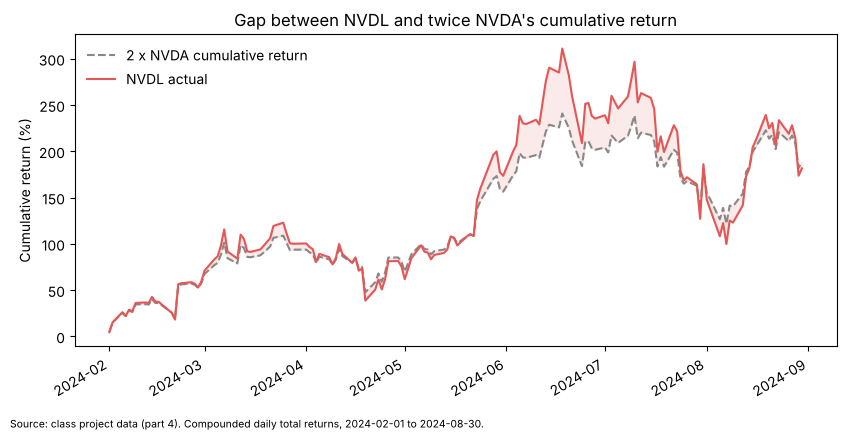

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
cum = (1 + df).cumprod() - 1
ax.plot(cum.index, 2 * cum["NVDA"] * 100, "--", color="#888", label="2 x NVDA cumulative return")
ax.plot(cum.index, cum["NVDL"] * 100, color="#E45756", label="NVDL actual")
ax.fill_between(cum.index, cum["NVDL"] * 100, 2 * cum["NVDA"] * 100, color="#E45756", alpha=0.12)
ax.set_ylabel("Cumulative return (%)"); ax.set_title("Gap between NVDL and twice NVDA's cumulative return")
ax.legend(frameon=False); fig.autofmt_xdate()
fig.text(0.01, -0.03, "Source: class project data (part 4). Compounded daily total returns, 2024-02-01 to 2024-08-30.", fontsize=7.5)
plt.tight_layout(); fig.savefig(FIG / "4F_gap_vs_2x.png", bbox_inches="tight"); plt.show()